# SIR epidemic as an agent-based model

1,600 people sit on a 40 × 40 grid (wrapping at the edges), each Susceptible, Infected or Recovered. Each step, every infected person infects each susceptible neighbour (8 around them) with probability β = 0.08, then recovers with probability γ = 0.10. All updates happen at once. Five people are infected at the start. Slides 24–27.

*Made for this site, following the rules on the slides (`1 Lecture/Agent Based Modelling with Mesa - Slides.html`). It uses Mesa 3 (`mesa.discrete_space`), tested with Mesa 3.5.1 in the browser. The interactive Solara versions on py.cafe, linked from the slides, need the internet and run outside this site.*

The chart on slide 26 is drawn from this notebook (seed 1).

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install mesa networkx

In [2]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, FixedAgent
import numpy as np
import matplotlib.pyplot as plt

**The model.** Two phases per step, so that someone infected this step cannot pass it on until the next step.

In [3]:
S, I, R = 0, 1, 2

class Person(FixedAgent):
    def __init__(self, model, cell):
        super().__init__(model)
        self.cell = cell
        self.state = S
        self.next_state = S

    def decide(self):
        self.next_state = self.state
        if self.state == S:
            k = sum(a.state == I for a in self.cell.neighborhood.agents)
            if k and self.random.random() < 1 - (1 - self.model.beta) ** k:   # each infected neighbour: chance beta
                self.next_state = I
        elif self.state == I and self.random.random() < self.model.gamma:
            self.next_state = R

    def update(self):
        self.state = self.next_state


class SIR(mesa.Model):
    def __init__(self, size=40, beta=0.08, gamma=0.10, initial_infected=5, seed=1):
        super().__init__(rng=seed)
        self.beta, self.gamma = beta, gamma
        self.grid = OrthogonalMooreGrid((size, size), torus=True, random=self.random)
        for cell in self.grid.all_cells:
            Person(self, cell)
        for p in self.random.sample(list(self.agents), initial_infected):
            p.state = I

    def step(self):
        self.agents.do("decide")
        self.agents.do("update")

    def counts(self):
        st = [a.state for a in self.agents]
        return st.count(S), st.count(I), st.count(R)

**Run until nobody is infected** (or 300 steps). Predict first: when does the infection peak, and does everyone catch it?

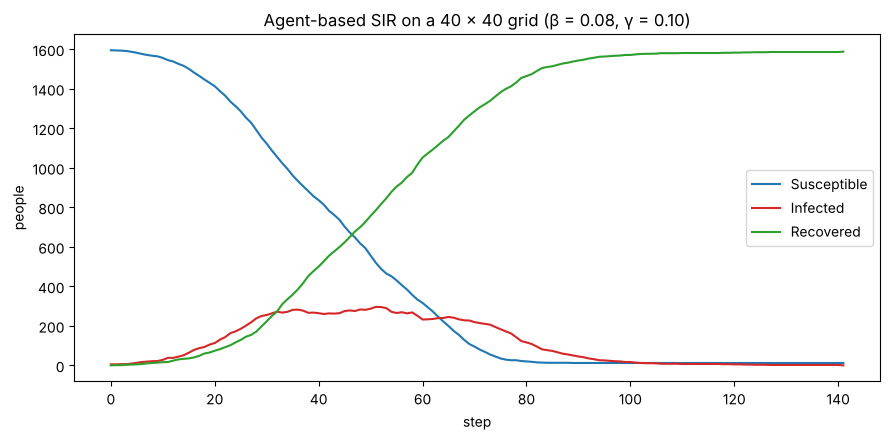

Peak: 296 infected at step 51; never infected: 12 of 1600; finished after 141 steps


In [4]:
model = SIR()
history = [model.counts()]
while history[-1][1] > 0 and len(history) < 300:
    model.step(); history.append(model.counts())
h = np.array(history)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(h[:, 0], label="Susceptible", color="tab:blue")
ax.plot(h[:, 1], label="Infected", color="tab:red")
ax.plot(h[:, 2], label="Recovered", color="tab:green")
ax.set(xlabel="step", ylabel="people", title="Agent-based SIR on a 40 × 40 grid (β = 0.08, γ = 0.10)")
ax.legend(); plt.tight_layout(); plt.show()
peak = int(np.argmax(h[:, 1]))
print(f"Peak: {h[peak, 1]} infected at step {peak}; never infected: {h[-1, 0]} of {h[0].sum()}; finished after {len(h) - 1} steps")

**Experiment.** Small changes in β have large effects. Compare the final number never infected:

In [5]:
for beta in (0.03, 0.05, 0.08, 0.12):
    m = SIR(beta=beta, seed=1); c = m.counts()
    while c[1] > 0:
        m.step(); c = m.counts()
    print(f"beta = {beta:.2f}: never infected {c[0]} of 1600")

beta = 0.03: never infected 1538 of 1600


beta = 0.05: never infected 87 of 1600


beta = 0.08: never infected 12 of 1600
beta = 0.12: never infected 2 of 1600
